# Tarea 1 – Parte 1: Recolección y limpieza de noticias peruanas

- **Fecha de descarga:** 2026-10-18
- **Opción elegida:** B – El Comercio
- **URL base:** https://elcomercio.pe
- **Fuentes:** sitemaps de noticias por sección (declarados en `robots.txt`):
  `https://elcomercio.pe/sitemap/news/{seccion}/?outputType=xml` para `politica`, `economia`, `deporte-total` y `tecnologia`.
- **Decisión metodológica:** el RSS oficial (`/arc/outboundfeeds/rss/category/...`) solo devuelve 13–17 noticias por sección
  (y 0 para `deportes`/`ciencias`), insuficiente para 350+. Se usaron los sitemaps de noticias (≈100 por sección), públicos y
  permitidos por `robots.txt`. La **bajada** se obtiene de la etiqueta `og:description` de cada artículo.
- **Buenas prácticas:** User-Agent descriptivo, pausa de 1.5 s entre solicitudes, máximo 1 reintento y respaldo crudo en `datos/raw/`.

In [1]:
import time
import xml.etree.ElementTree as ET
from datetime import date
from pathlib import Path
from urllib import robotparser

import requests
import pandas as pd
import plotly.express as px
import plotly.io as pio
from bs4 import BeautifulSoup

pio.renderers.default = "plotly_mimetype+png"  # interactivo en VS Code + imagen visible en GitHub
pd.set_option("display.max_colwidth", 120)

BASE = "https://elcomercio.pe"
HEADERS = {"User-Agent": "Mozilla/5.0 (Tarea academica QLAB-PUCP; clasificador de noticias; uso educativo)"}
PAUSA = 1.5
SECCIONES = ["politica", "economia", "deporte-total", "tecnologia"]
NS = {"s": "http://www.sitemaps.org/schemas/sitemap/0.9",
      "news": "http://www.google.com/schemas/sitemap-news/0.9"}
RAW = Path("datos/raw")
RAW.mkdir(parents=True, exist_ok=True)
print("Fecha de descarga:", date.today())

Fecha de descarga: 2026-10-18


## 1. Revisión de `robots.txt`

In [2]:
r = requests.get(f"{BASE}/robots.txt", headers=HEADERS, timeout=20)
(RAW / "robots.txt").write_text(r.text, encoding="utf-8")
rp = robotparser.RobotFileParser()
rp.parse(r.text.splitlines())

for s in SECCIONES:
    url = f"{BASE}/sitemap/news/{s}/?outputType=xml"
    print(url, "->", "permitido" if rp.can_fetch(HEADERS["User-Agent"], url) else "BLOQUEADO")
print("Artículos de noticia ->", "permitido" if rp.can_fetch(HEADERS["User-Agent"], f"{BASE}/politica/ejemplo-noticia/") else "BLOQUEADO")

https://elcomercio.pe/sitemap/news/politica/?outputType=xml -> permitido
https://elcomercio.pe/sitemap/news/economia/?outputType=xml -> permitido
https://elcomercio.pe/sitemap/news/deporte-total/?outputType=xml -> permitido
https://elcomercio.pe/sitemap/news/tecnologia/?outputType=xml -> permitido
Artículos de noticia -> permitido


## 2. Extracción

In [3]:
def get(url):
    """GET con pausa de 1.5 s y como máximo 1 reintento."""
    for intento in range(2):
        try:
            r = requests.get(url, headers=HEADERS, timeout=20)
            if r.status_code == 200:
                return r
            print(f"  HTTP {r.status_code} en {url}")
        except requests.RequestException as e:
            print(f"  Error: {e}")
        finally:
            time.sleep(PAUSA)
    return None

In [4]:
filas = []
for s in SECCIONES:
    url = f"{BASE}/sitemap/news/{s}/?outputType=xml"
    r = get(url)
    if r is None:
        print("No se pudo descargar", url)
        continue
    (RAW / f"sitemap_{s}.xml").write_bytes(r.content)  # respaldo crudo
    for u in ET.fromstring(r.content).findall("s:url", NS):
        loc = u.findtext("s:loc", namespaces=NS).strip()
        filas.append({
            "titular": (u.findtext("news:news/news:title", namespaces=NS) or "").strip(),
            "medio": "El Comercio",
            "seccion_original": "/".join(loc.split("/")[3:-2]),  # ej. economia/mercados
            "url": loc,
            "fecha": (u.findtext("news:news/news:publication_date", namespaces=NS) or "")[:10],
            "sitemap": s,
        })

crudo = pd.DataFrame(filas)
print(crudo.shape)
crudo["sitemap"].value_counts()

(400, 6)


sitemap
politica         100
economia         100
deporte-total    100
tecnologia       100
Name: count, dtype: int64

La bajada se descarga de cada artículo (≈400 solicitudes con pausa de 1.5 s). Si el respaldo crudo ya existe, se carga en lugar de volver a descargar.

In [5]:
def obtener_bajada(url):
    r = get(url)
    if r is None:
        return ""
    soup = BeautifulSoup(r.text, "html.parser")
    for attrs in ({"property": "og:description"}, {"name": "description"}):
        m = soup.find("meta", attrs=attrs)
        if m and m.get("content"):
            return m["content"].strip()
    return ""

ruta_crudo = RAW / "noticias_crudo.csv"
if ruta_crudo.exists():
    crudo = pd.read_csv(ruta_crudo)
    print("Respaldo crudo cargado (no se vuelve a descargar):", crudo.shape)
else:
    bajadas = []
    for i, u in enumerate(crudo["url"], 1):
        bajadas.append(obtener_bajada(u))
        if i % 50 == 0:
            print(f"{i}/{len(crudo)} descargadas")
    crudo["bajada"] = bajadas
    crudo.to_csv(ruta_crudo, index=False, encoding="utf-8")
    print("Guardado", ruta_crudo, crudo.shape)

Respaldo crudo cargado (no se vuelve a descargar): (400, 7)


## 3. Limpieza y normalización

In [6]:
df = crudo.copy()
reporte = {"descargadas": len(df)}

df["titular"] = df["titular"].fillna("").str.strip()
df["bajada"] = df["bajada"].fillna("").str.strip()

antes = len(df); df = df.drop_duplicates(subset="url");     reporte["duplicado_url"] = antes - len(df)
antes = len(df); df = df[df["titular"] != ""];              reporte["titular_vacio"] = antes - len(df)
antes = len(df); df = df.drop_duplicates(subset="titular"); reporte["titular_repetido"] = antes - len(df)
reporte

{'descargadas': 400,
 'duplicado_url': 1,
 'titular_vacio': 0,
 'titular_repetido': 0}

### Tabla de equivalencias `seccion_original` → categoría final

In [7]:
MAPEO = {"politica": "politica", "economia": "economia",
         "deporte-total": "deportes", "tecnologia": "ciencia_tecnologia"}

df["etiqueta"] = df["seccion_original"].str.split("/").str[0].map(MAPEO)

tabla_mapeo = (df.assign(etiqueta=df["etiqueta"].fillna("DESCARTADA"))
                 .groupby(["seccion_original", "etiqueta"]).size()
                 .reset_index(name="n_noticias")
                 .sort_values(["etiqueta", "n_noticias"], ascending=[True, False]))
tabla_mapeo

,seccion_original,etiqueta,n_noticias
20,opinion/columnistas,DESCARTADA,6
11,ecdata,DESCARTADA,4
0,bbc-news-mundo,DESCARTADA,2
29,ruedas-tuercas/automotriz,DESCARTADA,2
18,eldominical/ciencia,DESCARTADA,1
19,elecciones,DESCARTADA,1
30,tecnologia/actualidad,ciencia_tecnologia,37
35,tecnologia/inteligencia-artificial,ciencia_tecnologia,19
32,tecnologia/ciencias,ciencia_tecnologia,10
31,tecnologia/ciberseguridad,ciencia_tecnologia,7


### Noticias descartadas y motivos

In [8]:
descartadas = df[df["etiqueta"].isna()]
reporte["fuera_de_las_4_categorias"] = len(descartadas)
print("Descartadas por no encajar en las 4 categorías (aparecen en el sitemap pero pertenecen a otra sección del diario):")
display(descartadas[["titular", "seccion_original"]])

df = df[df["etiqueta"].notna()].reset_index(drop=True)
reporte["finales"] = len(df)
pd.Series(reporte, name="n").to_frame()

Descartadas por no encajar en las 4 categorías (aparecen en el sitemap pero pertenecen a otra sección del diario):


,titular,seccion_original
9,Cómo entender el Congreso peruano,opinion/columnistas
10,Empiecen a gobernar,opinion/columnistas
16,La dispersión del voto creció en las últimas elecciones municipales en Lima Metropolitana: ¿Cuántos distritos y qué ...,ecdata
27,“Amarrando la chiva”,opinion/columnistas
48,"Si no es por el fondo, al menos por las formas",opinion/columnistas
57,Elecciones municipales 2026: Casi mil candidatos limeños cambiaron de camiseta política,ecdata
68,Una conferencia legislativa,opinion/columnistas
86,"¡A serenarse, señora Fujimori!",opinion/columnistas
90,Avanza País solicita al JNE que realice una segunda vuelta para la Alcaldía de Lima,elecciones
111,"Fenómeno El Niño: Presupuesto para prevención y respuesta ante desastres caería en 8,2% en el 2027",ecdata


,n
descargadas,400
duplicado_url,1
titular_vacio,0
titular_repetido,0
fuera_de_las_4_categorias,16
finales,383


## 4. Análisis exploratorio (EDA)

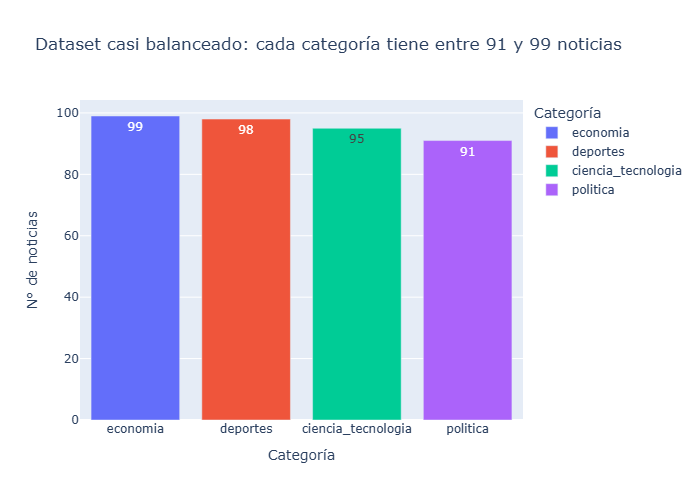

In [9]:
conteo = df["etiqueta"].value_counts().reset_index()
fig1 = px.bar(conteo, x="etiqueta", y="count", text="count", color="etiqueta",
              title=f"Dataset casi balanceado: cada categoría tiene entre {conteo['count'].min()} y {conteo['count'].max()} noticias",
              labels={"etiqueta": "Categoría", "count": "N° de noticias"})
fig1.show()

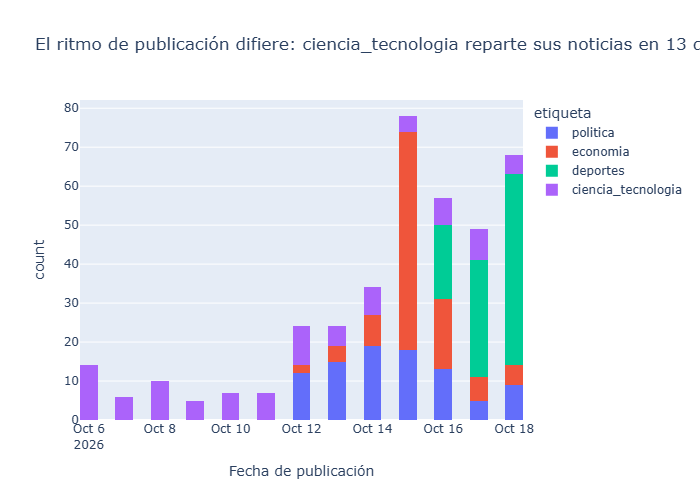

,dias_cubiertos
etiqueta,
ciencia_tecnologia,13
deportes,3
economia,7
politica,7


In [10]:
df["fecha"] = pd.to_datetime(df["fecha"])
dias = df.groupby("etiqueta")["fecha"].agg(lambda s: (s.max() - s.min()).days + 1)
fig2 = px.histogram(df, x="fecha", color="etiqueta", nbins=30,
                    title=f"El ritmo de publicación difiere: {dias.idxmax()} reparte sus noticias en {dias.max()} días, {dias.idxmin()} en solo {dias.min()}",
                    labels={"fecha": "Fecha de publicación", "count": "N° de noticias"})
fig2.show()
dias.rename("dias_cubiertos").to_frame()

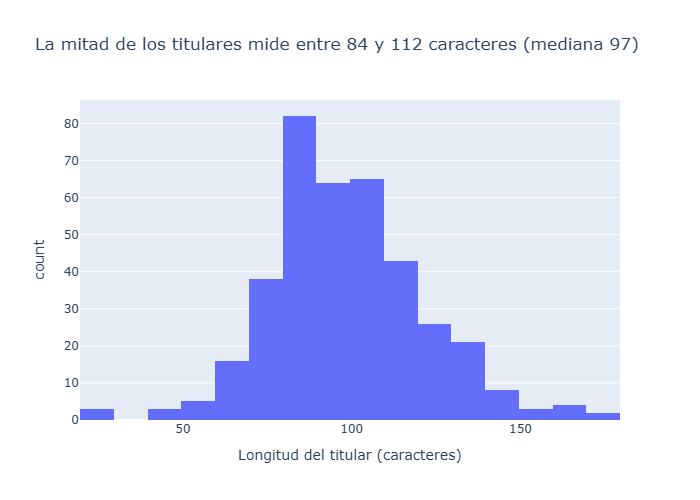

,count,mean,std,min,25%,50%,75%,max
etiqueta,,,,,,,,
ciencia_tecnologia,95.0,91.8,15.5,59.0,83.0,93.0,101.5,138.0
deportes,98.0,97.7,23.7,56.0,82.2,92.0,106.8,178.0
economia,99.0,95.7,28.5,22.0,77.5,89.0,119.5,153.0
politica,91.0,110.0,18.3,69.0,98.5,109.0,120.0,166.0


In [11]:
df["largo"] = df["titular"].str.len()
q1, med, q3 = df["largo"].quantile([.25, .5, .75]).astype(int)
fig3 = px.histogram(df, x="largo", nbins=30,
                    title=f"La mitad de los titulares mide entre {q1} y {q3} caracteres (mediana {med})",
                    labels={"largo": "Longitud del titular (caracteres)"})
fig3.show()
df.groupby("etiqueta")["largo"].describe().round(1)

## 5. Validación: titulares más largos y más cortos

In [12]:
print("5 titulares MÁS LARGOS")
display(df.nlargest(5, "largo")[["titular", "largo", "etiqueta"]])
print("5 titulares MÁS CORTOS")
display(df.nsmallest(5, "largo")[["titular", "largo", "etiqueta"]])

5 titulares MÁS LARGOS


,titular,largo,etiqueta
214,"“El jugador peruano tiene un déficit grande en nutrición y táctica que resuelve a los 20 años, eso en Argentina es a...",178,deportes
215,El furioso “Que se dedique a administrar” de Guede a Franco Velazco y un Quevedo que reconquistó a Comando Sur: Lo q...,171,deportes
267,“Creo que puedo llegar a un top 3 sin que nadie se quede botado”: Raúl ‘Mono’ Orlandini le responde a El Comercio so...,167,deportes
58,"Keiko Fujimori sobre Álvaro Vargas Llosa: “Confío en que su trayectoria, experiencia y compromiso contribuirán a for...",166,politica
54,"Juan Sheput sobre eventual suspensión del viaje del papa León XIV al Perú: “Es posible, pero todavía no está la pala...",160,politica


5 titulares MÁS CORTOS


,titular,largo,etiqueta
155,Invocación por el Perú,22,economia
99,AlaCena no tiene precio,23,economia
117,IA y Sandbox regulatorio,24,economia
169,La evolución de la confianza en los pagos,41,economia
100,Premio Nobel de Economía: la macro es micro,43,economia


Verificación de que las URLs funcionan (10 al azar, con pausa):

In [13]:
estado = []
for u in df.sample(10, random_state=42)["url"]:
    estado.append(requests.head(u, headers=HEADERS, timeout=20, allow_redirects=True).status_code)
    time.sleep(PAUSA)
print("Códigos HTTP:", estado)

Códigos HTTP: [200, 200, 200, 200, 200, 200, 200, 200, 200, 200]


## 6. Exportación

In [14]:
COLS = ["titular", "bajada", "medio", "seccion_original", "url", "fecha", "etiqueta"]
df["fecha"] = df["fecha"].dt.strftime("%Y-%m-%d")
df[COLS].to_csv("datos/noticias.csv", index=False, encoding="utf-8")
print(df[COLS].shape)
df[COLS].head()

(383, 7)


,titular,bajada,medio,seccion_original,url,fecha,etiqueta
0,Diputados: Informe recomienda suspender por 120 días a Julián Pérez Mallqui por agresión a su expareja,La situación del diputado Julián Pérez Mallqui (Juntos por el Perú) se complica. La Comisión de Ética Parlamentaria ...,El Comercio,politica,https://elcomercio.pe/politica/diputados-informe-recomienda-suspender-por-120-dias-a-julian-perez-mallqui-por-agresi...,2026-10-18,politica
1,Campañas del “No a la Revocatoria” y Reelección Municipal: Caso contra Susana Villarán se encamina a los diez años s...,"El caso seguido contra la exalcaldesa de Lima, Susana Villarán, por la presunta recepción de dinero ilícito para sus...",El Comercio,politica,https://elcomercio.pe/politica/susana-villaran-caso-contra-exalcaldesa-por-presuntas-irregularidades-en-las-campanas...,2026-10-18,politica
2,Álvaro Vargas Llosa: “EE.UU. nos está ayudando a recuperar la soberanía que las mafias ponen en peligro”,"Álvaro Vargas Llosa Asumirá el cargo el 16 de noviembre, pero en esta conversación adelanta lo que serán varias clav...",El Comercio,politica,https://elcomercio.pe/politica/alvaro-vargas-llosa-eeuu-embajador-del-peru-en-estados-unidos-entrevista-noticia/,2026-10-18,politica
3,"El Senado también se la juega, una crónica de Fernando Vivas sobre la pugna por las facultades legislativas","Tras la agónica aprobación de facultades acotadas en Diputados, con Fuerza Popular apostando al todo o nada; en el s...",El Comercio,politica,https://elcomercio.pe/politica/el-senado-tambien-se-la-juega-una-cronica-de-fernando-vivas-congreso-facultades-legis...,2026-10-18,politica
4,Alejandro Aguinaga sobre su ausencia en debate de facultades por viajar a congreso médico: No puedo señalar cuál era...,El senador Alejandro Aguinaga se pronunció sobre su viaje a Argentina durante el debate de las facultades legislativ...,El Comercio,politica/congreso,https://elcomercio.pe/politica/congreso/alejandro-aguinaga-sobre-su-ausencia-en-debate-de-facultades-por-asistir-a-c...,2026-10-18,politica


## Conclusiones

1. **Volumen y balance:** de 400 noticias descargadas quedaron **383** (1 URL duplicada y 16 descartadas por pertenecer a otras secciones,
   como `opinion/columnistas`, `ecdata` o `bbc-news-mundo`). Las 4 categorías quedan casi balanceadas (91–99 noticias), por lo que
   no hace falta re-muestrear antes de entrenar.
2. **Ritmo de publicación:** deportes publica 98 noticias en solo 3 días, mientras ciencia y tecnología necesita 13 días para llegar a 95.
   El dataset es una "foto" reciente y la cobertura temporal no es uniforme entre secciones (posible sesgo hacia la coyuntura de octubre 2026).
3. **Longitud de titulares:** política tiene los titulares más largos (mediana 109 caracteres, frecuentemente con citas textuales
   "Fulano: «…»"), mientras economía tiene los más cortos y dispersos (columnas de opinión con titulares de 22–43 caracteres como
   *"AlaCena no tiene precio"*), que serán los más difíciles de clasificar solo con el titular.
4. **Descartes con contenido político:** algunas noticias descartadas (`elecciones`, `opinion/columnistas`) son claramente políticas,
   pero se respetó la regla de mapear solo por sección editorial para no introducir etiquetas manuales.